<a href="https://colab.research.google.com/github/Sarah-Jack05/encs4380-dynamics--Mazion-/blob/main/python/Module1_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

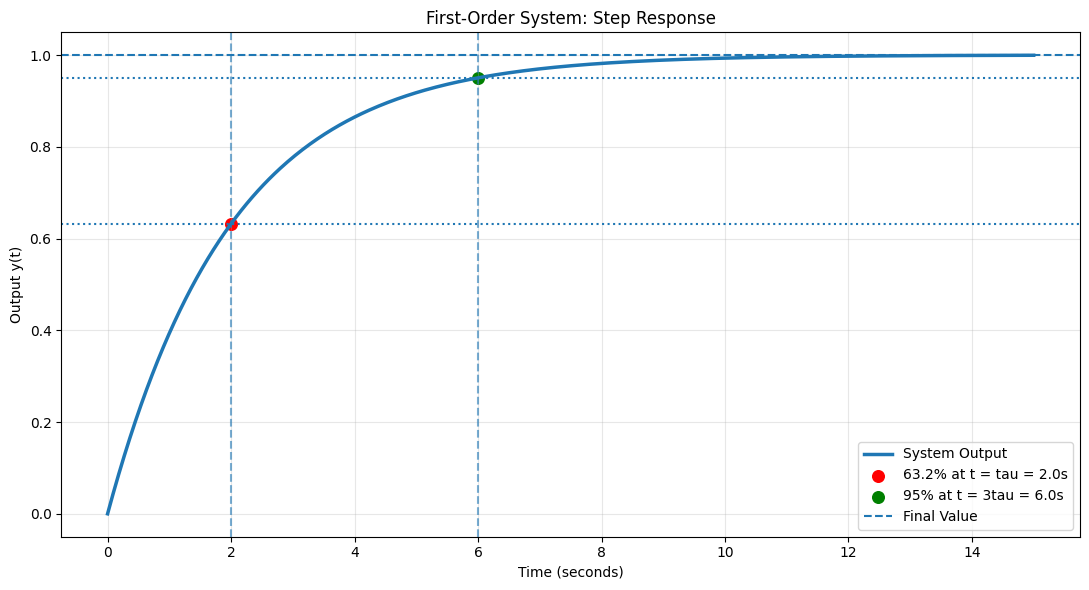

STEP RESPONSE RESULTS
---------------------
Time Constant: 2.0 seconds
Final Value: 1.0000
Output at tau: 0.6321
Output at 3tau: 0.9502


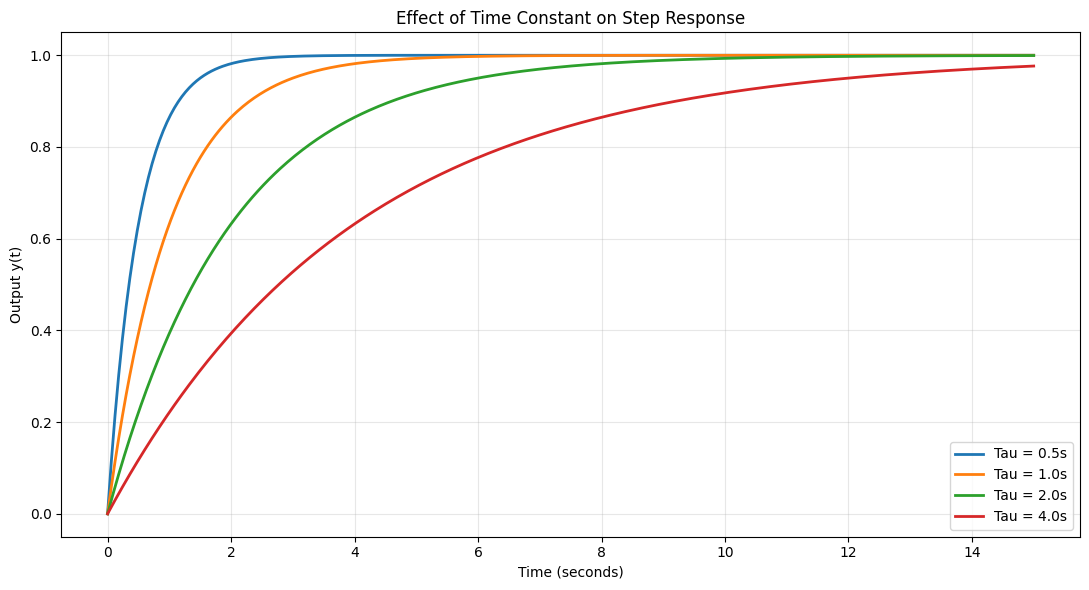

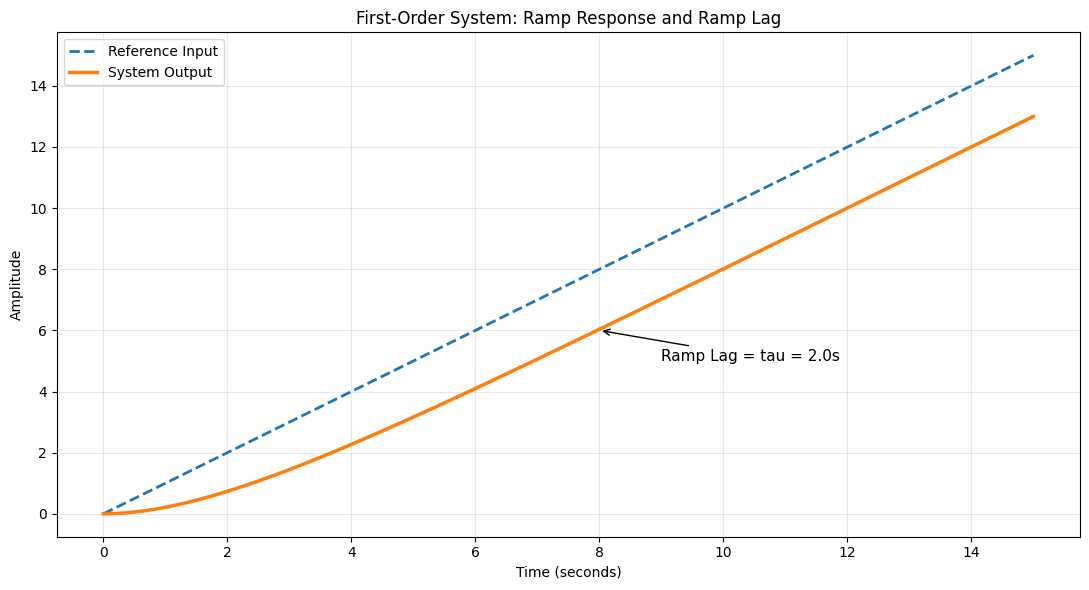

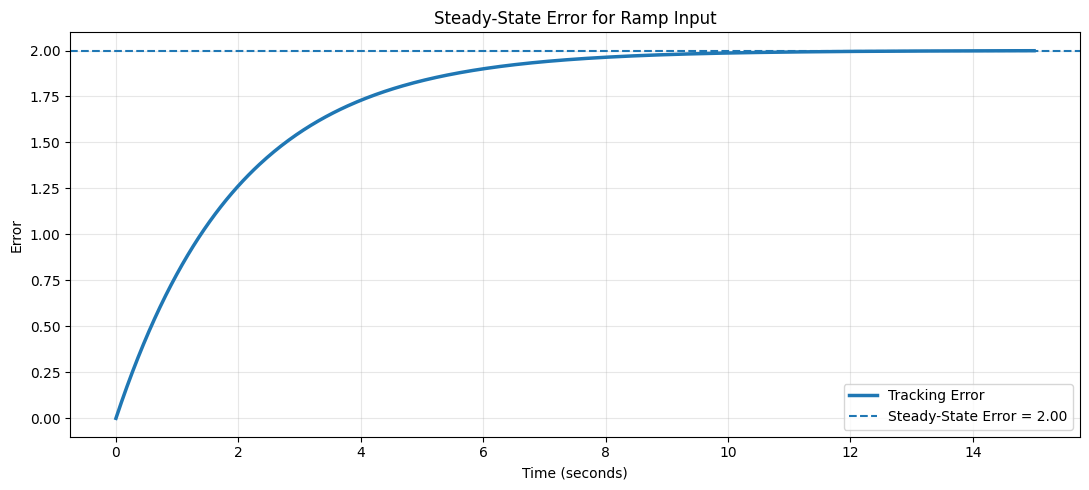


RAMP RESPONSE RESULTS
---------------------
Ramp Lag = 2.00 seconds
Steady-State Error = 2.0000
Final Simulated Error = 1.9989


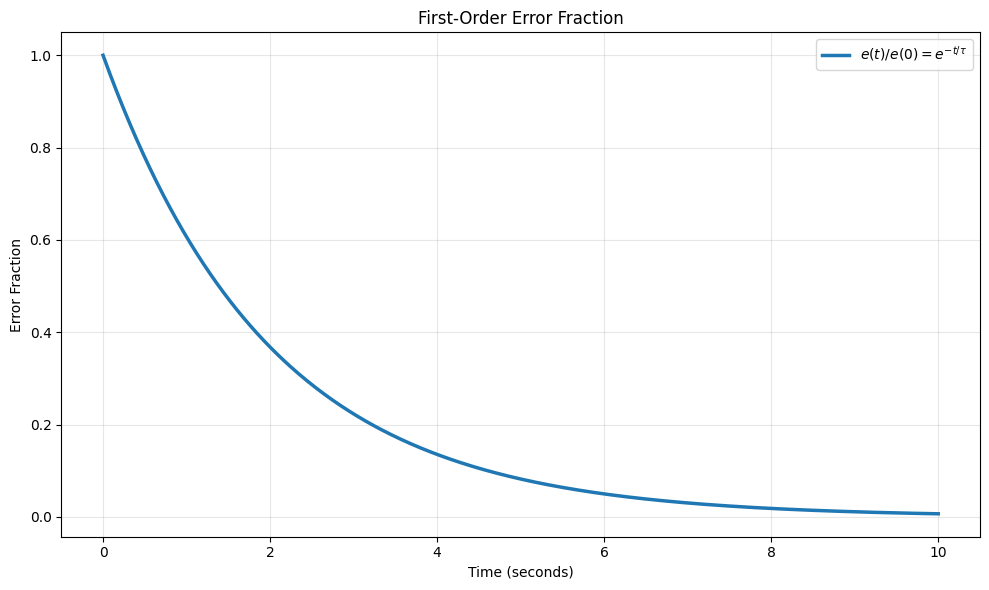

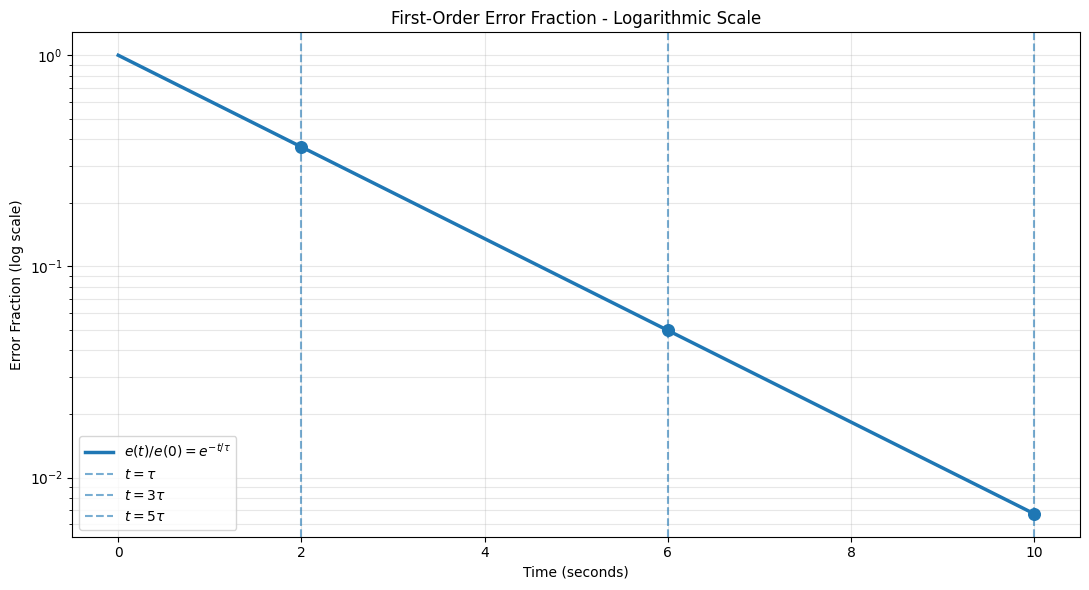


ERROR FRACTION RESULTS
----------------------
At t = tau:  0.3679 (36.79%)
At t = 3tau: 0.0498 (4.98%)
At t = 5tau: 0.0067 (0.67%)


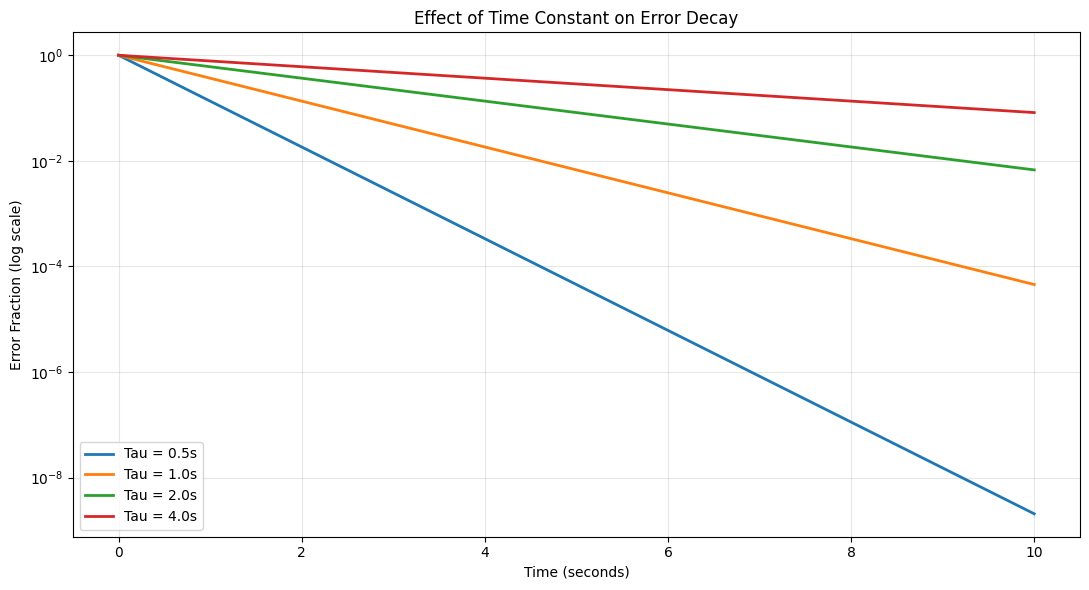

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# SYSTEM PARAMETERS
# ==================================================
K = 1.0
tau = 2.0
A = 1.0

# ==================================================
# 1. STEP RESPONSE + IMPORTANT POINTS
# ==================================================
t = np.linspace(0, 15, 500)
y = K * A * (1 - np.exp(-t / tau))

t1, t2 = tau, 3 * tau
y1 = K * A * (1 - np.exp(-t1 / tau))
y2 = K * A * (1 - np.exp(-t2 / tau))
final_value = K * A

plt.figure(figsize=(11, 6))
plt.plot(t, y, linewidth=2.5, label="System Output")

plt.scatter(t1, y1, color="red", s=70,
            label=f"63.2% at t = tau = {tau}s")
plt.scatter(t2, y2, color="green", s=70,
            label=f"95% at t = 3tau = {3*tau}s")

plt.axhline(final_value, linestyle="--", label="Final Value")
plt.axhline(0.632 * final_value, linestyle=":")
plt.axhline(0.95 * final_value, linestyle=":")
plt.axvline(tau, linestyle="--", alpha=0.6)
plt.axvline(3*tau, linestyle="--", alpha=0.6)

plt.xlabel("Time (seconds)")
plt.ylabel("Output y(t)")
plt.title("First-Order System: Step Response")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("STEP RESPONSE RESULTS")
print("---------------------")
print(f"Time Constant: {tau} seconds")
print(f"Final Value: {final_value:.4f}")
print(f"Output at tau: {y1:.4f}")
print(f"Output at 3tau: {y2:.4f}")


# ==================================================
# 2. EFFECT OF TIME CONSTANT ON STEP RESPONSE
# ==================================================
tau_values = [0.5, 1.0, 2.0, 4.0]
t = np.linspace(0, 15, 500)

plt.figure(figsize=(11, 6))

for current_tau in tau_values:
    y = K * A * (1 - np.exp(-t / current_tau))
    plt.plot(t, y, linewidth=2,
             label=f"Tau = {current_tau}s")

plt.xlabel("Time (seconds)")
plt.ylabel("Output y(t)")
plt.title("Effect of Time Constant on Step Response")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ==================================================
# 3. RAMP RESPONSE + RAMP LAG
# ==================================================
t = np.linspace(0, 15, 500)

input_signal = K * A * t

output_signal = K * A * (
    t - tau + tau * np.exp(-t / tau)
)

plt.figure(figsize=(11, 6))

plt.plot(t, input_signal, "--", linewidth=2,
         label="Reference Input")

plt.plot(t, output_signal, linewidth=2.5,
         label="System Output")

plt.annotate(
    f"Ramp Lag = tau = {tau}s",
    xy=(8, K*A*(8-tau)),
    xytext=(9, 5),
    arrowprops=dict(arrowstyle="->"),
    fontsize=11
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("First-Order System: Ramp Response and Ramp Lag")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ==================================================
# 4. STEADY-STATE ERROR FOR RAMP INPUT
# ==================================================
error = input_signal - output_signal
steady_state_error = K * A * tau

plt.figure(figsize=(11, 5))

plt.plot(t, error, linewidth=2.5,
         label="Tracking Error")

plt.axhline(
    steady_state_error,
    linestyle="--",
    label=f"Steady-State Error = {steady_state_error:.2f}"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Error")
plt.title("Steady-State Error for Ramp Input")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nRAMP RESPONSE RESULTS")
print("---------------------")
print(f"Ramp Lag = {tau:.2f} seconds")
print(f"Steady-State Error = {steady_state_error:.4f}")
print(f"Final Simulated Error = {error[-1]:.4f}")


# ==================================================
# 5. ERROR FRACTION - LINEAR SCALE
# ==================================================
t = np.linspace(0, 10, 500)
error_fraction = np.exp(-t / tau)

plt.figure(figsize=(10, 6))

plt.plot(
    t, error_fraction, linewidth=2.5,
    label=r"$e(t)/e(0)=e^{-t/\tau}$"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Error Fraction")
plt.title("First-Order Error Fraction")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ==================================================
# 6. ERROR FRACTION - LOGARITHMIC SCALE
#    WITH IMPORTANT POINTS
# ==================================================
t_tau = tau
t_3tau = 3 * tau
t_5tau = 5 * tau

e_tau = np.exp(-t_tau / tau)
e_3tau = np.exp(-t_3tau / tau)
e_5tau = np.exp(-t_5tau / tau)

plt.figure(figsize=(11, 6))

plt.plot(
    t, error_fraction, linewidth=2.5,
    label=r"$e(t)/e(0)=e^{-t/\tau}$"
)

plt.scatter(
    [t_tau, t_3tau, t_5tau],
    [e_tau, e_3tau, e_5tau],
    s=70, zorder=3
)

for time, label in [
    (t_tau, r"$t=\tau$"),
    (t_3tau, r"$t=3\tau$"),
    (t_5tau, r"$t=5\tau$")
]:
    plt.axvline(time, linestyle="--", alpha=0.6, label=label)

plt.yscale("log")
plt.xlabel("Time (seconds)")
plt.ylabel("Error Fraction (log scale)")
plt.title("First-Order Error Fraction - Logarithmic Scale")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nERROR FRACTION RESULTS")
print("----------------------")
print(f"At t = tau:  {e_tau:.4f} ({e_tau*100:.2f}%)")
print(f"At t = 3tau: {e_3tau:.4f} ({e_3tau*100:.2f}%)")
print(f"At t = 5tau: {e_5tau:.4f} ({e_5tau*100:.2f}%)")


# ==================================================
# 7. EFFECT OF TIME CONSTANT ON ERROR DECAY
# ==================================================
tau_values = [0.5, 1.0, 2.0, 4.0]
t = np.linspace(0, 10, 500)

plt.figure(figsize=(11, 6))

for current_tau in tau_values:
    error_fraction = np.exp(-t / current_tau)

    plt.plot(
        t, error_fraction, linewidth=2,
        label=f"Tau = {current_tau}s"
    )

plt.yscale("log")
plt.xlabel("Time (seconds)")
plt.ylabel("Error Fraction (log scale)")
plt.title("Effect of Time Constant on Error Decay")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
